# Moderação Socioeconômica: AFD x INSE nas Redes Públicas

## 1. Configuração e Recorte das Redes Públicas

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Caminhos do projeto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
INDICADORES = ROOT / "data" / "processed" / "indicadores"
ENEM = ROOT / "data" / "processed" / "enem"
FIGURAS = ROOT / "results" / "figuras"
TABELAS = ROOT / "results" / "tabelas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

# Padrão visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})
ORDEM_REDE = ["Federal", "Privada", "Municipal", "Estadual"]
CORES_REDE = {"Federal": "#1b9e77", "Privada": "#7570b3", "Municipal": "#e6ab02", "Estadual": "#d95f02"}
FONTE = "Fonte: elaboração própria a partir de INEP (ENEM 2024, Censo Escolar 2024 e INSE 2023)."
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_rows(40)


def salvar(fig, nome):
    # Adiciona a fonte no rodapé e exporta em 300 DPI
    fig.text(0.01, -0.03, FONTE, fontsize=8, color="gray", ha="left")
    fig.savefig(FIGURAS / nome)
    plt.show()


# Base analítica: escolas pareadas Censo x ENEM com ao menos 10 presentes
base = (
    pl.read_parquet(INDICADORES / "indicadores_ensino_medio_2024.parquet")
    .join(pl.read_parquet(ENEM / "enem_escolas_2024.parquet"), left_on="CO_ENTIDADE", right_on="CO_ESCOLA", how="inner")
    .filter(pl.col("IN_MIN_10_ALUNOS"))
)
print(f"Escolas analisadas: {base.height:,}")

Escolas analisadas: 22,999


In [2]:
def ajustar(formula, dados, cluster="CO_MUNICIPIO"):
    # MQO com erros-padrão agrupados (cluster) e controle de nulos
    df = dados.to_pandas()
    grupos = df[cluster].astype("category").cat.codes.to_numpy()
    return smf.ols(formula, data=df).fit(cov_type="cluster", cov_kwds={"groups": grupos})


def estrelas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def extrair(modelo, nome):
    # Coeficientes (sem dummies de UF), N e R² ajustado em formato longo
    ci = modelo.conf_int()
    linhas = [
        {"MODELO": nome, "TERMO": t, "COEF": modelo.params[t], "EP_CLUSTER": modelo.bse[t],
         "IC95_INF": ci.loc[t, 0], "IC95_SUP": ci.loc[t, 1], "P_VALOR": modelo.pvalues[t]}
        for t in modelo.params.index if not t.startswith("C(SG_UF")
    ]
    linhas.append({"MODELO": nome, "TERMO": "N", "COEF": float(modelo.nobs)})
    linhas.append({"MODELO": nome, "TERMO": "R2_AJUSTADO", "COEF": modelo.rsquared_adj})
    return pl.DataFrame(linhas, schema={"MODELO": pl.String, "TERMO": pl.String, "COEF": pl.Float64,
                                        "EP_CLUSTER": pl.Float64, "IC95_INF": pl.Float64,
                                        "IC95_SUP": pl.Float64, "P_VALOR": pl.Float64})


def quadro(tabela):
    # Quadro compacto: coeficiente (erro-padrão) com estrelas de significância
    return (
        tabela.with_columns(
            pl.when(pl.col("EP_CLUSTER").is_null())
            .then(pl.col("COEF").round(3).cast(pl.String))
            .otherwise(
                pl.format("{} ({}){}", pl.col("COEF").round(3), pl.col("EP_CLUSTER").round(3),
                          pl.col("P_VALOR").map_elements(estrelas, return_dtype=pl.String))
            ).alias("VALOR")
        )
        .pivot(on="MODELO", index="TERMO", values="VALOR", aggregate_function="first")
    )


# Escolas públicas com INSE válido; AFD (por +10 p.p.) e INSE centralizados na média
REGRESSORES = ["AFD_MED_CAT_1", "AFD_MED_CAT_3", "MEDIA_INSE", "TDI_MED_TOTAL", "ATU_MED_TOTAL",
               "DSU_MED_DOC_SUPERIOR", "TX_ABSTENCAO_DIA2", "NO_CATEGORIA", "SG_UF", "CO_MUNICIPIO"]
pub = (
    base.filter(pl.col("NO_DEPENDENCIA").is_in(["Estadual", "Federal", "Municipal"]))
    .drop_nulls(REGRESSORES)
    .with_columns(
        ((pl.col("AFD_MED_CAT_3") - pl.col("AFD_MED_CAT_3").mean()) / 10).alias("AFD_G3_C"),
        ((pl.col("AFD_MED_CAT_1") - pl.col("AFD_MED_CAT_1").mean()) / 10).alias("AFD_G1_C"),
        (pl.col("MEDIA_INSE") - pl.col("MEDIA_INSE").mean()).alias("INSE_C"),
    )
)
MEDIA_INSE = pub["MEDIA_INSE"].mean()
REDE = 'C(NO_DEPENDENCIA, Treatment(reference="Estadual"))'
CONTROLES = "TDI_MED_TOTAL + ATU_MED_TOTAL + DSU_MED_DOC_SUPERIOR + TX_ABSTENCAO_DIA2 + C(NO_CATEGORIA) + C(SG_UF)"
print(f"Escolas públicas: {pub.height:,} | INSE médio = {MEDIA_INSE:.2f}")
display(pub["NO_DEPENDENCIA"].value_counts())

Escolas públicas: 16,133 | INSE médio = 4.90


NO_DEPENDENCIA,count
str,u32
"""Estadual""",15562
"""Municipal""",88
"""Federal""",483


## 2. Desempenho por Estrato do INSE e Perfil Docente

INSE_CLASSIFICACAO,Intermediária,Alta docência fora da área (G3 ≥ 35%),Alta adequação (G1 ≥ 75%)
str,u32,u32,u32
"""Nível II""",361,305,136
"""Nível III""",1398,987,1119
"""Nível IV""",1259,766,1836
"""Nível V""",2126,1601,2356
"""Nível VI""",630,416,743
"""Nível VII""",18,5,70


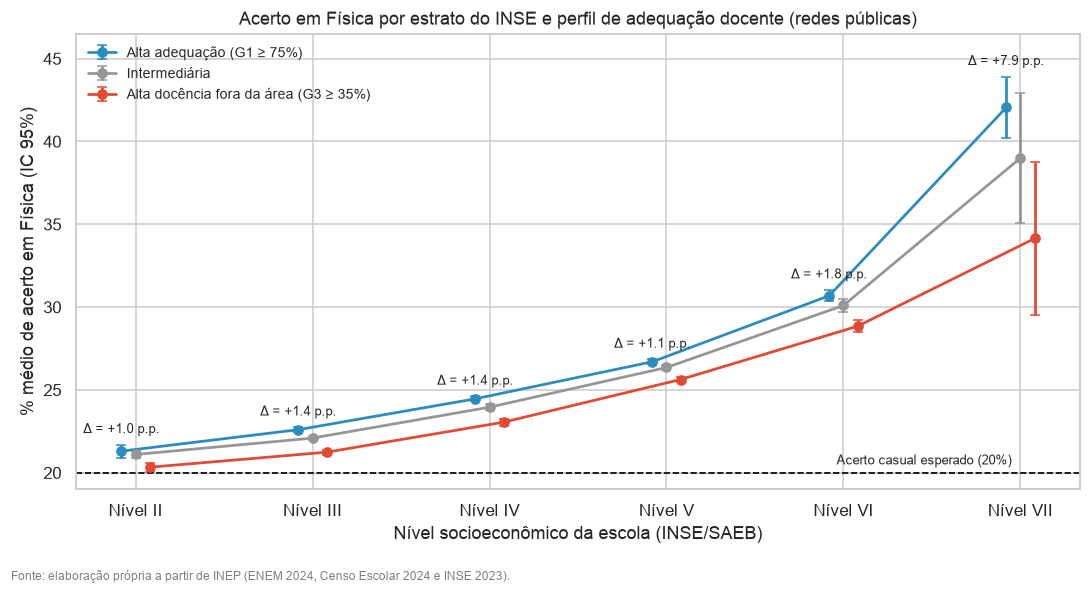

In [3]:
# Perfis mutuamente exclusivos de exposição docente (G1 >= 75% e G3 >= 35% não coexistem)
NIVEIS = ["Nível II", "Nível III", "Nível IV", "Nível V", "Nível VI", "Nível VII"]
PERFIS = {"Alta adequação (G1 ≥ 75%)": "#2b8cbe", "Intermediária": "#969696", "Alta docência fora da área (G3 ≥ 35%)": "#e34a33"}

estratos = (
    pub.filter(pl.col("INSE_CLASSIFICACAO").is_in(NIVEIS))
    .with_columns(
        pl.when(pl.col("AFD_MED_CAT_1") >= 75).then(pl.lit(list(PERFIS)[0]))
        .when(pl.col("AFD_MED_CAT_3") >= 35).then(pl.lit(list(PERFIS)[2]))
        .otherwise(pl.lit(list(PERFIS)[1])).alias("PERFIL")
    )
    .group_by("INSE_CLASSIFICACAO", "PERFIL")
    .agg(pl.len().alias("N"), pl.col("PCT_ACERTO_FISICA").mean().alias("MEDIA"),
         pl.col("PCT_ACERTO_FISICA").std().alias("DP"))
    .with_columns((1.96 * pl.col("DP") / pl.col("N").sqrt()).alias("IC95"))
)
display(estratos.pivot(on="PERFIL", index="INSE_CLASSIFICACAO", values="N")
        .sort(pl.col("INSE_CLASSIFICACAO").replace_strict({n: i for i, n in enumerate(NIVEIS)})))

fig, ax = plt.subplots(figsize=(10, 5.2))
for k, (perfil, cor) in enumerate(PERFIS.items()):
    d = estratos.filter(pl.col("PERFIL") == perfil).sort(pl.col("INSE_CLASSIFICACAO").replace_strict({n: i for i, n in enumerate(NIVEIS)}))
    x = np.array([NIVEIS.index(n) for n in d["INSE_CLASSIFICACAO"]]) + (k - 1) * 0.08
    ax.errorbar(x, d["MEDIA"], yerr=d["IC95"], fmt="-o", color=cor, capsize=3, label=perfil, lw=1.8)

# Diferença entre os perfis extremos em cada estrato
ext = estratos.pivot(on="PERFIL", index="INSE_CLASSIFICACAO", values="MEDIA")
ext_ic = estratos.pivot(on="PERFIL", index="INSE_CLASSIFICACAO", values="IC95")
for n in NIVEIS:
    linha = ext.filter(pl.col("INSE_CLASSIFICACAO") == n)
    linha_ic = ext_ic.filter(pl.col("INSE_CLASSIFICACAO") == n)
    if linha.height and linha[list(PERFIS)[0]][0] is not None and linha[list(PERFIS)[2]][0] is not None:
        gap = linha[list(PERFIS)[0]][0] - linha[list(PERFIS)[2]][0]
        topo = linha[list(PERFIS)[0]][0] + (linha_ic[list(PERFIS)[0]][0] or 0.0)
        ax.annotate(f"Δ = {gap:+.1f} p.p.", (NIVEIS.index(n) - 0.08, topo + 0.7), ha="center", fontsize=8.5)

ax.axhline(20, ls="--", color="black", lw=1.1)
ax.text(4.95, 20.5, "Acerto casual esperado (20%)", ha="right", fontsize=8.5)
ax.set_ylim(19, 46.5)
ax.set_xticks(range(len(NIVEIS)), NIVEIS)
ax.set_xlabel("Nível socioeconômico da escola (INSE/SAEB)")
ax.set_ylabel("% médio de acerto em Física (IC 95%)")
ax.set_title("Acerto em Física por estrato do INSE e perfil de adequação docente (redes públicas)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
salvar(fig, "fig05_fisica_estrato_inse_perfil_afd.png")

## 3. Modelo Econométrico de Moderação (AFD x INSE)

In [4]:
# Interação centralizada: beta3 < 0 favorece o Bloqueio Estrutural; beta3 > 0 a Escola Compensatória
mod_g3 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G3_C * INSE_C + {REDE} + {CONTROLES}", pub)
mod_g1 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G1_C * INSE_C + {REDE} + {CONTROLES}", pub)

CHAVE = ["AFD_G3_C", "AFD_G1_C", "INSE_C", "AFD_G3_C:INSE_C", "AFD_G1_C:INSE_C", "N", "R2_AJUSTADO"]
mod_tab = pl.concat([extrair(mod_g3, "G3_COMPLETA"), extrair(mod_g1, "G1_COMPLETA")])
display(quadro(mod_tab.filter(pl.col("TERMO").is_in(CHAVE))))

# Centralização: VIF baixo entre efeitos principais e interação
X = pub.select("AFD_G3_C", "INSE_C", (pl.col("AFD_G3_C") * pl.col("INSE_C")).alias("INTER"), "TDI_MED_TOTAL").to_numpy()
X = np.column_stack([np.ones(len(X)), X])
print("VIF:", {n: round(variance_inflation_factor(X, i + 1), 2) for i, n in enumerate(["AFD_G3_C", "INSE_C", "AFD_G3_C:INSE_C", "TDI"])})

TERMO,G3_COMPLETA,G1_COMPLETA
str,str,str
"""AFD_G3_C""","""-0.166 (0.024)***""",null
"""INSE_C""","""4.977 (0.139)***""","""5.037 (0.139)***"""
"""AFD_G3_C:INSE_C""","""-0.362 (0.04)***""",null
"""N""","""16133.0""","""16133.0"""
"""R2_AJUSTADO""","""0.556""","""0.555"""
"""AFD_G1_C""",null,"""0.127 (0.023)***"""
"""AFD_G1_C:INSE_C""",null,"""0.329 (0.039)***"""


VIF: {'AFD_G3_C': np.float64(1.03), 'INSE_C': np.float64(1.32), 'AFD_G3_C:INSE_C': np.float64(1.03), 'TDI': np.float64(1.31)}


## 4. Curva de Efeito Marginal Condicional

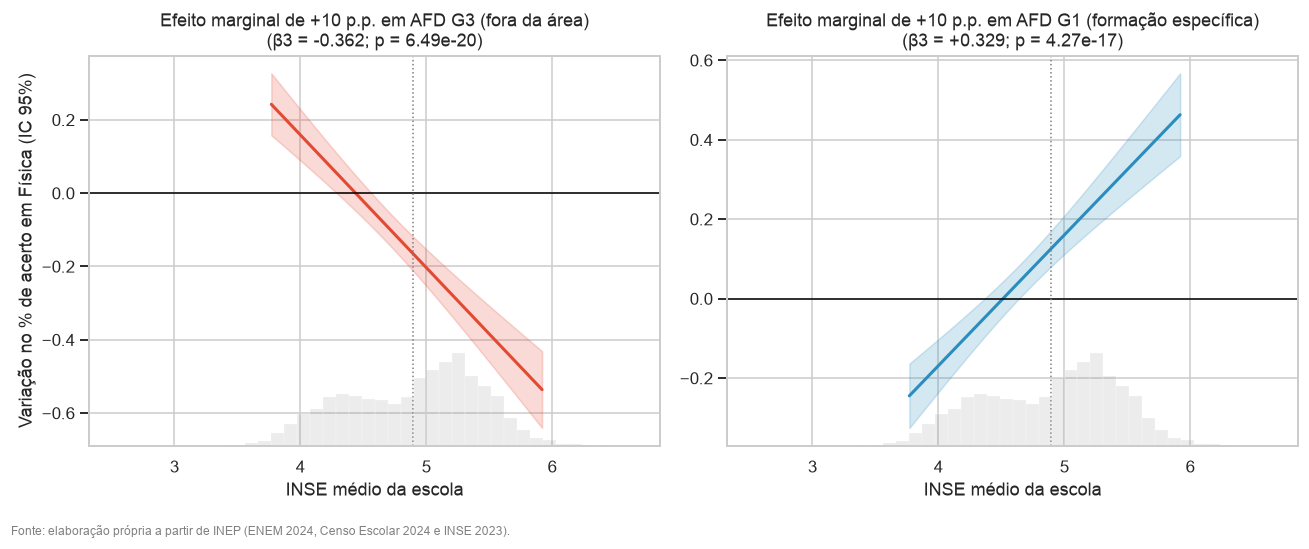

In [5]:
# dFísica/dAFD = b1 + b3 * INSE_C, com IC 95% pela matriz de covariância clusterizada
grade = np.linspace(pub["MEDIA_INSE"].quantile(0.01), pub["MEDIA_INSE"].quantile(0.99), 100)
z = grade - MEDIA_INSE

def efeito_marginal(m, afd):
    t = f"{afd}:INSE_C"
    V = m.cov_params()
    me = m.params[afd] + m.params[t] * z
    ep = np.sqrt(V.loc[afd, afd] + z ** 2 * V.loc[t, t] + 2 * z * V.loc[afd, t])
    return me, me - 1.96 * ep, me + 1.96 * ep

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, (m, afd, rot, cor) in zip(eixos, [(mod_g3, "AFD_G3_C", "AFD G3 (fora da área)", "#e34a33"),
                                          (mod_g1, "AFD_G1_C", "AFD G1 (formação específica)", "#2b8cbe")]):
    me, lo, hi = efeito_marginal(m, afd)
    ax.plot(grade, me, color=cor, lw=2)
    ax.fill_between(grade, lo, hi, color=cor, alpha=0.2)
    ax.axhline(0, color="black", lw=1)
    ax.axvline(MEDIA_INSE, color="gray", ls=":", lw=1)
    ax.set_title(f"Efeito marginal de +10 p.p. em {rot}\n(β3 = {m.params[afd + ':INSE_C']:+.3f}; p = {m.pvalues[afd + ':INSE_C']:.3g})")
    ax.set_xlabel("INSE médio da escola")
    # Distribuição do INSE no rodapé do painel
    ax2 = ax.twinx()
    ax2.hist(pub["MEDIA_INSE"].to_numpy(), bins=40, color="gray", alpha=0.15)
    ax2.set_yticks([])
    ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
eixos[0].set_ylabel("Variação no % de acerto em Física (IC 95%)")
fig.tight_layout()
salvar(fig, "fig06_efeito_marginal_condicional_inse.png")

## 5. Análise de Sensibilidade (≥ 30 Presentes)

In [6]:
# Reestimação restrita a escolas com ao menos 30 presentes no 2º dia (atrição amostral)
pub30 = pub.filter(pl.col("QTD_PRESENTES_DIA2") >= 30)
s_g3 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G3_C * INSE_C + {REDE} + {CONTROLES}", pub30)
s_g1 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G1_C * INSE_C + {REDE} + {CONTROLES}", pub30)

tab04 = pl.concat([mod_tab, extrair(s_g3, "G3_MIN30"), extrair(s_g1, "G1_MIN30")]).filter(pl.col("TERMO").is_in(CHAVE))
tab04.write_csv(TABELAS / "tab04_moderacao_inse_sensibilidade.csv")
quadro(tab04)

TERMO,G3_COMPLETA,G1_COMPLETA,G3_MIN30,G1_MIN30
str,str,str,str,str
"""AFD_G3_C""","""-0.166 (0.024)***""",null,"""-0.16 (0.03)***""",null
"""INSE_C""","""4.977 (0.139)***""","""5.037 (0.139)***""","""5.074 (0.163)***""","""5.142 (0.164)***"""
"""AFD_G3_C:INSE_C""","""-0.362 (0.04)***""",null,"""-0.436 (0.047)***""",null
"""N""","""16133.0""","""16133.0""","""10020.0""","""10020.0"""
"""R2_AJUSTADO""","""0.556""","""0.555""","""0.679""","""0.678"""
"""AFD_G1_C""",null,"""0.127 (0.023)***""",null,"""0.108 (0.03)***"""
"""AFD_G1_C:INSE_C""",null,"""0.329 (0.039)***""",null,"""0.368 (0.046)***"""
